In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

In [2]:
torch.manual_seed(42)

In [3]:
# Check for GPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [4]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/zalando-research/fashionmnist/fashion-mnist_test.csv
/kaggle/input/datasets/zalando-research/fashionmnist/fashion-mnist_train.csv
/kaggle/input/datasets/zalando-research/fashionmnist/t10k-images-idx3-ubyte
/kaggle/input/datasets/zalando-research/fashionmnist/t10k-labels-idx1-ubyte
/kaggle/input/datasets/zalando-research/fashionmnist/train-images-idx3-ubyte
/kaggle/input/datasets/zalando-research/fashionmnist/train-labels-idx1-ubyte


In [5]:
train_df = pd.read_csv('/kaggle/input/datasets/zalando-research/fashionmnist/fashion-mnist_train.csv')
train_df.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [6]:
train_df.shape

(60000, 785)

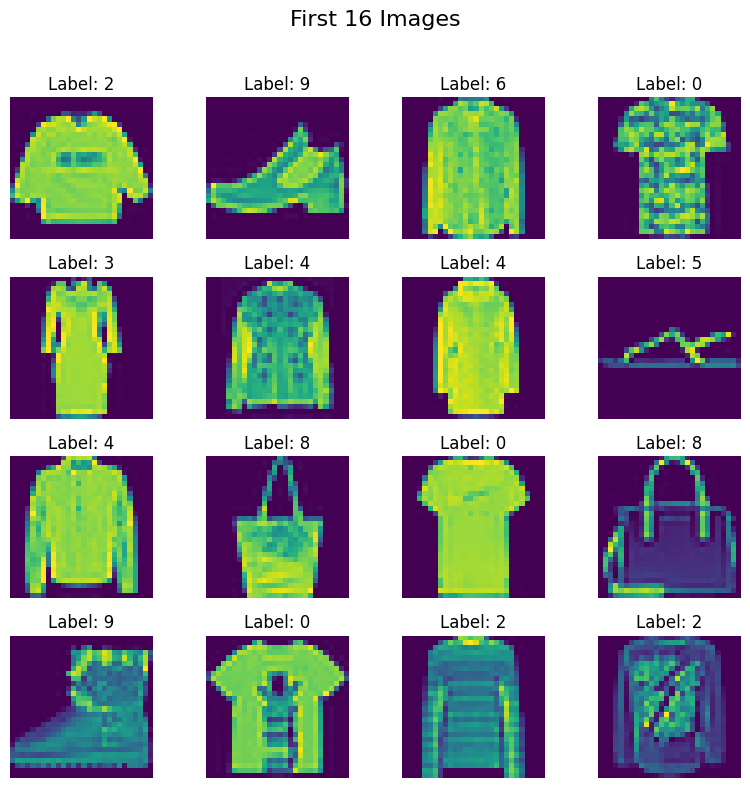

In [7]:
# visualizing first few images

fig, axes = plt.subplots(4, 4, figsize=(8, 8))
fig.suptitle("First 16 Images", fontsize=16)

for i, ax in enumerate(axes.flat):
    img = train_df.iloc[i, 1:].values.reshape(28, 28) # reshape to 28 x 28
    ax.imshow(img)
    ax.axis('off')
    ax.set_title(f"Label: {train_df.iloc[i, 0]}")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [8]:
train_df["label"].value_counts()

label
2    6000
9    6000
6    6000
0    6000
3    6000
4    6000
5    6000
8    6000
7    6000
1    6000
Name: count, dtype: int64

In [9]:
X = train_df.drop(columns=["label"])
y = train_df[["label"]]

In [10]:
# transformations
# required as it will be going to be trained by VGG need compatible one
# https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.vgg16.html


# 1. reshape - 784 (1D) -> 28 * 28 (2D) - greyscale
# 2. datatype - np.uint8
# 3. 1D -3D (3, 28, 28) - greyscale to color
# 4. tensor - PIL image - (3, 28, 28) 
# 5. resize - (3, 256, 256)
# 6. Center Crop - (3, 224, 224)
# 7. tensor scale -> (0, 1)
# 8. Normalize - (1 - mean) / std

In [11]:
from torchvision.transforms import transforms

custom_transformations = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [12]:
import torch
from torch.utils.data import Dataset
from PIL import Image
import numpy as np

class CustomDataset(Dataset):
    def __init__(self, features, labels, transforms=None):
        self.features = features.to_numpy() if hasattr(features, "to_numpy") else np.array(features)
        self.labels = labels.to_numpy() if hasattr(labels, "to_numpy") else np.array(labels)
        self.transforms = transforms

    def __len__(self):
        return len(self.features)

    def __getitem__(self, index):
        # extract feature row and reshape
        image = self.features[index].reshape(28, 28)
        
        #  format as RGB image array (H, W, C)
        image = image.astype(np.uint8)
        image = np.stack([image] * 3, axis=-1)
        image = Image.fromarray(image)
        
        # transformation
        if self.transforms:
            image = self.transforms(image)
        label = torch.as_tensor(self.labels[index], dtype=torch.long)

        return image, label

In [13]:
train_data = CustomDataset(X, y, transforms=custom_transformations)

In [14]:
train_loader = DataLoader(train_data, batch_size=32, shuffle=True, pin_memory=True)

In [15]:
# Model
import torchvision.models as models

vgg16 = models.vgg16(pretrained=True)

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [16]:
vgg16

VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

In [17]:
vgg16.classifier

Sequential(
  (0): Linear(in_features=25088, out_features=4096, bias=True)
  (1): ReLU(inplace=True)
  (2): Dropout(p=0.5, inplace=False)
  (3): Linear(in_features=4096, out_features=4096, bias=True)
  (4): ReLU(inplace=True)
  (5): Dropout(p=0.5, inplace=False)
  (6): Linear(in_features=4096, out_features=1000, bias=True)
)

In [18]:
# freezing training for feature extarction layer not much info to be trained on
# common cnn reduce the size in first few laeyrs on cnn
for param in vgg16.features.parameters():
    param.requires_grad = False # wont calculate gradient

In [19]:
# remove vgg 16 classifier and add classifier for our dataset
# vgg16 - 1000 classes
# our dataset - 10 classes

vgg16.classifier = nn.Sequential(
    nn.Linear(25088, 1024),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(1024, 512),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(512, 10),
    # nn.Linear(512, 128),
    # nn.ReLU(),
    # nn.Dropout(0.5),
    # nn.Linear(128, 10),
)

In [20]:
vgg16 = vgg16.to(device)

In [21]:
learning_rate = 0.0001
epochs = 10

In [22]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(vgg16.classifier.parameters(), lr=learning_rate)

In [24]:
%%time
# training loop

for epoch in range(epochs):
    total_epoch_loss = 0
    for batch_features, batch_labels in train_loader:

        # Moving batch_features and batch_labels on GPU
        batch_features = batch_features.to(device)
        batch_labels = batch_labels.to(device)
        
        # forward pass
        out = vgg16(batch_features)

        # calculate loss
        batch_labels = batch_labels.squeeze(1).long() 
        loss = criterion(out, batch_labels)

        # backpass 
        optimizer.zero_grad()
        loss.backward()
        total_epoch_loss += loss.item()

        # update gradient
        optimizer.step()
    
    # printing average epoch loss
    print(f"Epoch {epoch + 1}/{epochs} - Loss: {total_epoch_loss/len(train_loader)}")

avg_loss = total_epoch_loss / len(train_loader)

Epoch 1/10 - Loss: 0.34614637757142386
Epoch 2/10 - Loss: 0.20924852676937977
Epoch 3/10 - Loss: 0.16685508625780543
Epoch 4/10 - Loss: 0.1301703764018292
Epoch 5/10 - Loss: 0.10417448372592529
Epoch 6/10 - Loss: 0.08525106364826983
Epoch 7/10 - Loss: 0.07199860969274305
Epoch 8/10 - Loss: 0.055007698864505315
Epoch 9/10 - Loss: 0.049765733690730604
Epoch 10/10 - Loss: 0.04238418864934162
CPU times: user 1h 17min 39s, sys: 4min 28s, total: 1h 22min 8s
Wall time: 1h 2min 15s


In [25]:
test_df = pd.read_csv("/kaggle/input/datasets/zalando-research/fashionmnist/fashion-mnist_test.csv")

In [26]:
X_test = test_df.drop(columns=["label"])
y_test = test_df["label"]

In [27]:
test_data = CustomDataset(X_test, y_test, transforms=custom_transformations)
test_loader = DataLoader(test_data, batch_size=32, shuffle=True, pin_memory=True)

In [29]:
# need to tell model that it is being evaluated
# need as different behaviour during training and prediction
vgg16.eval()

VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

In [32]:
import torch
import torch.nn as nn # For the loss function
from tqdm import tqdm # For the progress bar
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def evaluate_model(model, test_loader, class_names):
    """
    Evaluates the performance of a PyTorch model on a test dataset.

    Args:
        model (nn.Module): The trained PyTorch model.
        test_loader (DataLoader): DataLoader for the test dataset.
        class_names (list): List of class names for the classification report.
    """
    # 1. Device Setup
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)
    model.eval() # Set the model to evaluation mode
    criterion = nn.CrossEntropyLoss()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0
    
    # Lists to store all predictions and true labels for detailed metrics
    all_predictions = []
    all_targets = []

    # 2. Evaluation Loop
    with torch.no_grad(): # Disable gradient calculations
        # Add tqdm for a progress bar during evaluation
        for batch_features, batch_targets in tqdm(test_loader, desc="Evaluating"):
            
            # Insert this logic inside the evaluation loop:
            if batch_targets.dim() > 1 and batch_targets.size(1) > 1:
                # Converts one-hot targets back to class indices for CrossEntropyLoss
                batch_targets = torch.argmax(batch_targets, dim=1)
            # Move data to the appropriate device
            batch_features = batch_features.to(device)
            batch_targets = batch_targets.to(device)


            # Forward pass
            out = model(batch_features)
            
            # Calculate Loss
            loss = criterion(out, batch_targets)
            total_loss += loss.item() * batch_features.size(0) # Accumulate loss

            # Get predicted class (index with the highest probability)
            _, predicted = torch.max(out, 1)

            # Update accuracy metrics
            total_samples += batch_targets.size(0)
            total_correct += (predicted == batch_targets).sum().item()
            
            # Store predictions and targets for scikit-learn metrics
            all_predictions.extend(predicted.cpu().numpy())
            all_targets.extend(batch_targets.cpu().numpy())

    # 3. Calculate Final Metrics
    avg_loss = total_loss / total_samples
    accuracy = total_correct / total_samples

    print("\n" + "="*50)
    print("## ✨ Final Performance Metrics")
    print(f"Test Loss: {avg_loss:.4f}")
    print(f"Test Accuracy: {accuracy:.4f} ({total_correct}/{total_samples})")
    print("="*50 + "\n")

    # 4. Generate Classification Report
    print("## 📋 Classification Report")
    print(classification_report(all_targets, all_predictions, target_names=class_names, digits=4))

    # 5. Visualize Confusion Matrix
    print("## 🖼️ Confusion Matrix")
    # 
    cm = confusion_matrix(all_targets, all_predictions)
    
    plt.figure(figsize=(10, 8))
    sns.heatmap(
        cm, 
        annot=True, 
        fmt='d', 
        cmap='Blues', 
        xticklabels=class_names, 
        yticklabels=class_names
    )
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title('Confusion Matrix')
    plt.show()


In [33]:
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", 
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

Evaluating: 100%|██████████| 313/313 [01:05<00:00,  4.75it/s]



## ✨ Final Performance Metrics
Test Loss: 0.2731
Test Accuracy: 0.9339 (9339/10000)

## 📋 Classification Report
              precision    recall  f1-score   support

 T-shirt/top     0.8612    0.9060    0.8830      1000
     Trouser     0.9940    0.9900    0.9920      1000
    Pullover     0.9117    0.8880    0.8997      1000
       Dress     0.9017    0.9630    0.9313      1000
        Coat     0.9178    0.8930    0.9052      1000
      Sandal     0.9909    0.9840    0.9875      1000
       Shirt     0.8253    0.7700    0.7967      1000
     Sneaker     0.9691    0.9710    0.9700      1000
         Bag     0.9900    0.9940    0.9920      1000
  Ankle boot     0.9751    0.9800    0.9776      1000

    accuracy                         0.9339     10000
   macro avg     0.9337    0.9339    0.9335     10000
weighted avg     0.9337    0.9339    0.9335     10000

## 🖼️ Confusion Matrix


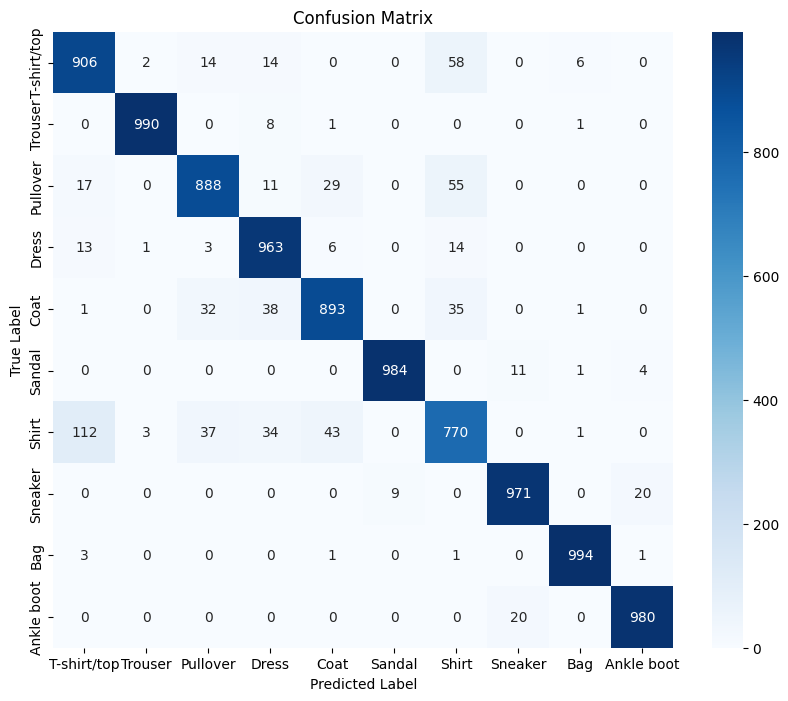

In [35]:
evaluate_model(vgg16, test_loader, class_names) 